In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving X_test.csv to X_test.csv
Saving X_train.csv to X_train.csv
Saving y_test.csv to y_test.csv
Saving y_train.csv to y_train.csv


Training data shape: (5634, 30)
Testing data shape: (1409, 30)
Training labels shape: (5634,)
Testing labels shape: (1409,)
Logistic Regression Accuracy: 0.8069552874378992
Percentage: 80.7 %
Decision Tree Accuracy: 0.794180269694819
Percentage: 79.42 %
                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.806955         80.70
1        Decision Tree  0.794180         79.42


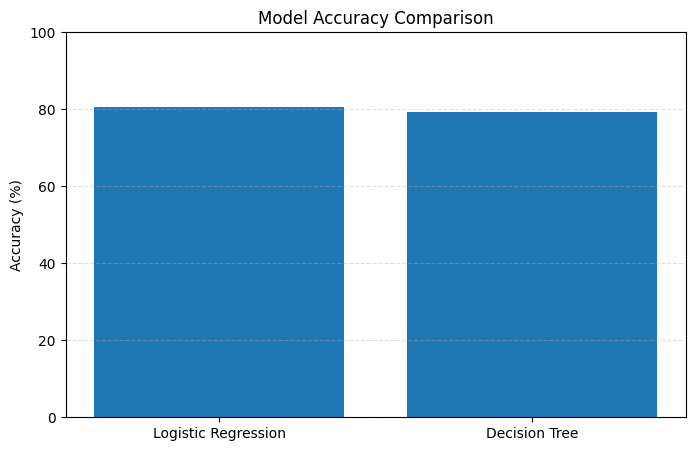

In [3]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy)
print("Percentage:", round(lr_accuracy * 100, 2), "%")
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)
print("Percentage:", round(dt_accuracy * 100, 2), "%")

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
).round(2)

print(comparison)
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.savefig("model_accuracy_comparison.png",
            dpi=300, bbox_inches="tight")

plt.show()

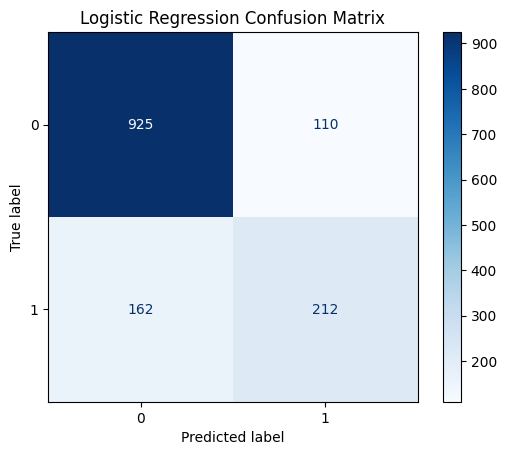

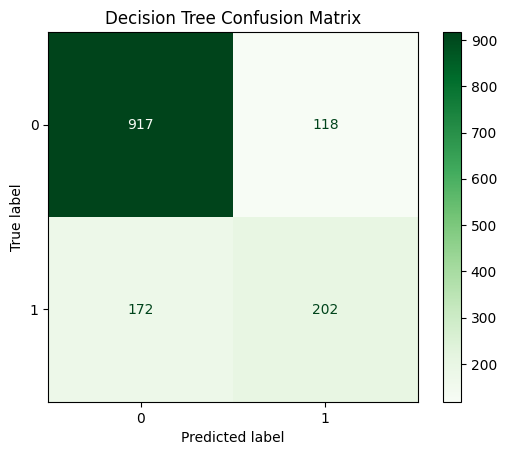

Logistic Regression performed better.
Saved files:
1. logistic_regression_cm.png
2. decision_tree_cm.png
3. model_accuracy_comparison.png
4. model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
lr_cm = confusion_matrix(y_test, lr_predictions)

lr_display = ConfusionMatrixDisplay(
    confusion_matrix=lr_cm
)

lr_display.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix")
plt.savefig("logistic_regression_cm.png",
            dpi=300, bbox_inches="tight")

plt.show()

dt_cm = confusion_matrix(y_test, dt_predictions)

dt_display = ConfusionMatrixDisplay(
    confusion_matrix=dt_cm
)

dt_display.plot(cmap="Greens", values_format="d")

plt.title("Decision Tree Confusion Matrix")
plt.savefig("decision_tree_cm.png",
            dpi=300, bbox_inches="tight")

plt.show()
if lr_accuracy > dt_accuracy:
    print("Logistic Regression performed better.")
elif dt_accuracy > lr_accuracy:
    print("Decision Tree performed better.")
else:
    print("Both models achieved the same accuracy.")
comparison.to_csv("model_comparison.csv", index=False)

print("Saved files:")
print("1. logistic_regression_cm.png")
print("2. decision_tree_cm.png")
print("3. model_accuracy_comparison.png")
print("4. model_comparison.csv")
from google.colab import files

files.download("logistic_regression_cm.png")
files.download("decision_tree_cm.png")
files.download("model_accuracy_comparison.png")
files.download("model_comparison.csv")